In [1]:
### Notes

### - mostly doesn't work for the no rotation case

### - what about set up two non overlap Gaussian blob test
###   and see how the distance varies over rotation (at one fixed angle)
###   should be constant and equal to something like ||f|| + ||g||

### - timing isn't fair between L2 and SW because f is transformed multiple times for L2

In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

In [3]:
### INPUTS

het_vol_files = 'Data/het_models/'

n_vols = 10

scale = 2  # downsample scale

In [4]:
het_vols = []

vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
    
        v = transforms.block_average_downsample(v, scale)
        dx = dx * scale
            
        v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size  
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
        
        het_vols.append(v)
        mrc.close()

het_vols = np.array(het_vols)

f = het_vols[0].copy()

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


In [5]:
### Define constants

d = 3            # dimensons
M = f.shape[0]   # grid size LxLxL
N = f.shape[0]
max_l = M//2

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

### For Euclidean distance
h = 1/np.floor( (N+1+N%2)/2 )
dV = h**3

### For sliced Wasserstein distance
# z = np.linspace(-1, 1, N, endpoint=False)
z = np.linspace(0, 1, N, endpoint=True)  # EV: actually this is the t-grid now [0,1] , uniform
phis = np.linspace(0, 2*np.pi, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)

### EV: ARE ANY OF THESE CORRECT?
sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# sinthetas = np.sin(thetas)[:, np.newaxis, np.newaxis]
# sinthetas = np.sin(thetas)[np.newaxis, :, np.newaxis]

dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 

print(dV)
print(dVsphere)

2.7826474107465846e-05
7.41406580610679e-05


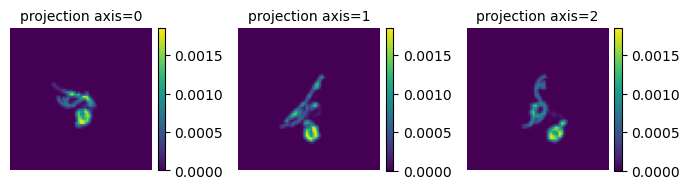

0.0 0.00035347196 0.12499999 0.9999999403953552


In [6]:
plots.orthogonal_2D_projection_plot(f)
print( np.amin(f), np.amax(f), np.sum(f), np.sum(f)*(dx**3) )

In [7]:
### Make the rotated volumes

het_vols_rotated = np.zeros(het_vols.shape)

for idx in range(n_vols):
    het_vols_rotated[idx] = het_vols[idx].copy()
    
    # het_vols_rotated[idx] = np.rot90(het_vols[idx].copy(), k=2)

    # rot_vol = transforms.rotate_voxel_zyz_fourier(het_vols[idx], 0.5*np.pi, 1.5*np.pi, 0.2*np.pi)
    # rot_vol = np.where(rot_vol<0, 0, rot_vol)
    # rot_vol = signals.Signal(rot_vol, d=3).preprocess_signals()[0]
    # het_vols_rotated[idx] = rot_vol

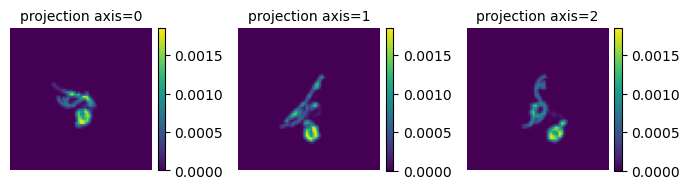

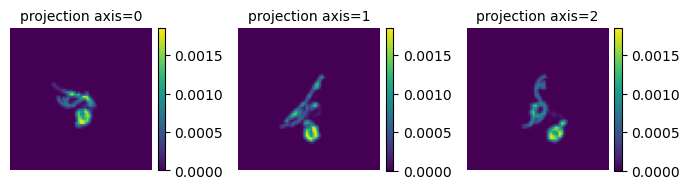

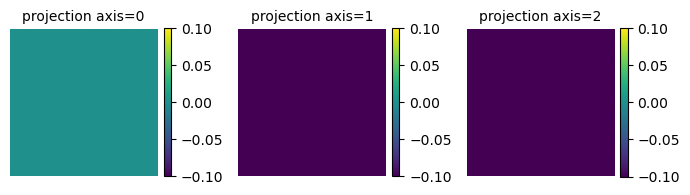

In [8]:
plots.orthogonal_2D_projection_plot(het_vols[0])
plots.orthogonal_2D_projection_plot(het_vols_rotated[0])
plots.orthogonal_2D_projection_plot(f - het_vols_rotated[0])

In [9]:
### Precompute for f

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, apply_ramp=True).signed_inverse_cdf_transform()

f_norm = np.sqrt(np.sum(f**2))
f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
f_tp_norm = np.sqrt(np.sum(f_tp[0]**2 * sinthetas))
f_tn_norm = np.sqrt(np.sum(f_tn[0]**2 * sinthetas))

In [10]:
### Compute the distances over rotations

### *** SHOULD THERE BE A PI/2 FOR THE SW CORRELATIONS ??? *** ###

corr_l2 = np.zeros(n_vols)
corr_sw = np.zeros(n_vols)
corr_rfsw = np.zeros(n_vols)

distances_l2 = np.zeros(n_vols)
distances_sw = np.zeros(n_vols)
distances_rfsw = np.zeros(n_vols)

for k in range(n_vols):

    print("Volume: ", k)

    g = het_vols_rotated[k]

    ### Euclidean distance
    t = time.time()
    g_norm = np.sqrt(np.sum(g**2))
    c_l2, R_idx = alignments.align_l2(np.flip(f, axis=2), np.flip(g, axis=2), fle)
    d_l2 = (f_norm**2 + g_norm**2) * dV - 2*c_l2
    corr_l2[k] = np.amax(c_l2)
    distances_l2[k] = np.amin(d_l2)
    print("alignment L2   = ", time.time() - t)
    print(R_idx)
    

    ### sliced 2-Wasserstein distance
    t = time.time()
    g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
    g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))
    c_sw, R_idx = alignments.fast_rotational_correlation(f_t, g_t, fle)
    d_sw = ((f_t_norm**2 + g_t_norm**2) * dVsphere - 2*c_sw) / (4*np.pi)
    corr_sw[k] = np.amax(c_sw)
    distances_sw[k] = np.amin(d_sw)
    print("alignment SW   = ", time.time() - t)
    print(R_idx)

    
    ### ramp-filtered sliced 2-Wasserstein distance
    t = time.time()
    g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    g_tp_norm = np.sqrt(np.sum(g_tp[0]**2 * sinthetas))
    g_tn_norm = np.sqrt(np.sum(g_tn[0]**2 * sinthetas))
    cp, R_idx = alignments.fast_rotational_correlation(f_tp[0], g_tp[0], fle)
    cn, R_idx = alignments.fast_rotational_correlation(f_tn[0], g_tn[0], fle)
    d_rfsw_p = ((f_tp_norm**2 + g_tp_norm**2) * dVsphere - 2*cp) / (4*np.pi)
    d_rfsw_n = ((f_tn_norm**2 + g_tn_norm**2) * dVsphere - 2*cn) / (4*np.pi)
    d_rfsw = (d_rfsw_p + d_rfsw_n) / 2
    corr_rfsw[k] = np.amax((cp + cn) / 2)
    distances_rfsw[k] = np.amin(d_rfsw)
    print("alignment RFSW   = ", time.time() - t)
    print(R_idx)
    
    print('\n')

Volume:  0
correlation R=0:  6.177408876913211e-10
all correlation:  5.78735243134969e-10
alignment L2   =  4.997639894485474
0
correlation R=0:  3.3608364446780623
all correlation:  3.360687924950892
alignment SW   =  5.846260070800781
0
correlation R=0:  3.8567580213671535
all correlation:  3.846939468589462
correlation R=0:  3.858007422839836
all correlation:  3.850030973015979
alignment RFSW   =  11.54243803024292
0


Volume:  1
correlation R=0:  4.598022513010453e-10
all correlation:  5.770787819177044e-10
alignment L2   =  4.955624103546143
1
correlation R=0:  3.3613687527529734
all correlation:  3.3622506252053643
alignment SW   =  5.759490728378296
1
correlation R=0:  3.870478680853407
all correlation:  3.8816573932269205
correlation R=0:  3.863145220456928
all correlation:  3.874395019146812
alignment RFSW   =  11.566771030426025
1


Volume:  2
correlation R=0:  3.631182953803651e-10
all correlation:  5.195644067152319e-10
alignment L2   =  5.035107135772705
1
correlation R=0:

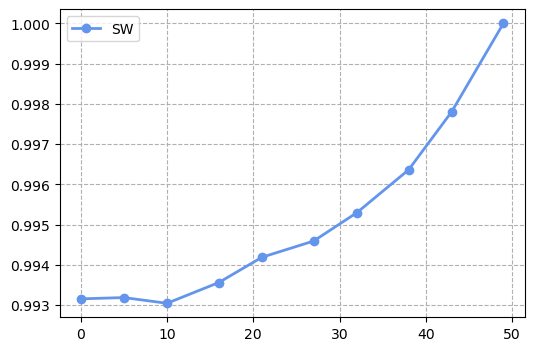

In [11]:
dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

plt.figure(figsize=(6,4))

# plt.plot(vol_idx, dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx, dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

# plt.plot(vol_idx, distances_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx, distances_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, distances_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [12]:
distances_l2

array([5.78815056e-11, 1.56003422e-10, 2.54687435e-10, 4.15981524e-10,
       4.67350163e-10, 5.43559600e-10, 5.75414230e-10, 5.67076357e-10,
       6.03582012e-10, 5.86430325e-10])

In [13]:
distances_sw

array([0.01884996, 0.01885118, 0.0188458 , 0.01886532, 0.01888919,
       0.01890451, 0.01893123, 0.01897173, 0.01902675, 0.01911058])

In [14]:
distances_rfsw

array([0.01982272, 0.02285666, 0.02446581, 0.02686983, 0.02859721,
       0.03125366, 0.0335609 , 0.03374682, 0.0338739 , 0.03570598])

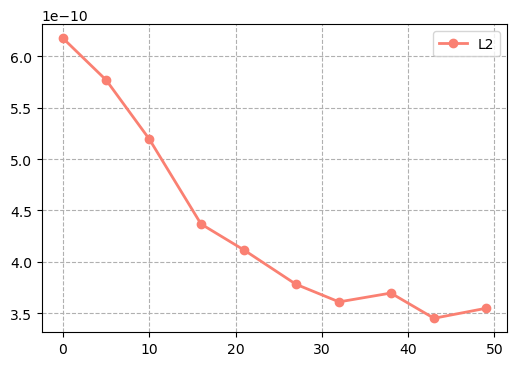

In [15]:
plt.figure(figsize=(6,4))

plt.plot(vol_idx, corr_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx, corr_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx, corr_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [16]:
# ## This is WITH the sin(thetas)

# # sinthetas = 1
# sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# # sinthetas = np.sin(thetas)[np.newaxis, :, np.newaxis]
# # sinthetas = np.sin(thetas)[:, np.newaxis, np.newaxis]

# f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
# zf = np.array([f_t_norm**2 for k in range(n_vols)])

# zg = np.zeros(n_vols)
# zgp = np.zeros(n_vols)
# zgn = np.zeros(n_vols)

# for k in range(n_vols):

#     g = het_vols_rotated[k]
    
#     g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
#     g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))
#     zg[k] = g_t_norm**2

#     g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()
#     g_tp_norm = np.sqrt(np.sum(g_tp[0]**2 * sinthetas))
#     g_tn_norm = np.sqrt(np.sum(g_tn[0]**2 * sinthetas))
#     zgp[k] = g_tp_norm**2
#     zgn[k] = g_tn_norm**2

In [17]:
## This is WITHOUT the sin(thetas)

f_t_norm = np.sqrt(np.sum(f_t**2))
zf = np.array([f_t_norm**2 for k in range(n_vols)])

zg = np.zeros(n_vols)
zgp = np.zeros(n_vols)
zgn = np.zeros(n_vols)

for k in range(n_vols):

    g = het_vols_rotated[k]
    
    g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
    g_t_norm = np.sqrt(np.sum(g_t**2))
    zg[k] = g_t_norm**2

    # g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    # g_tp_norm = np.sqrt(np.sum(g_tp[0]**2))
    # g_tn_norm = np.sqrt(np.sum(g_tn[0]**2))
    # zgp[k] = g_tp_norm**2
    # zgn[k] = g_tn_norm**2

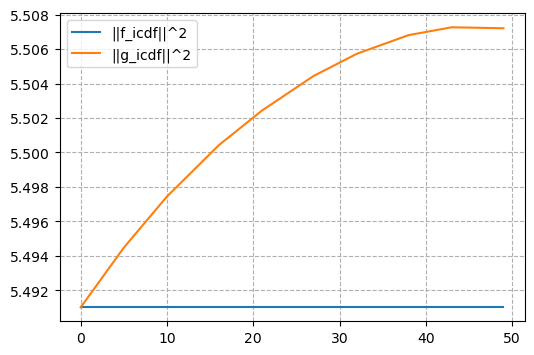

In [18]:
plt.figure(figsize=(6,4))
plt.plot(vol_idx, zf * dVsphere, label='||f_icdf||^2')
plt.plot(vol_idx, zg * dVsphere, label='||g_icdf||^2')
# plt.plot(zgp * dVsphere)
# plt.plot(zgn * dVsphere)
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

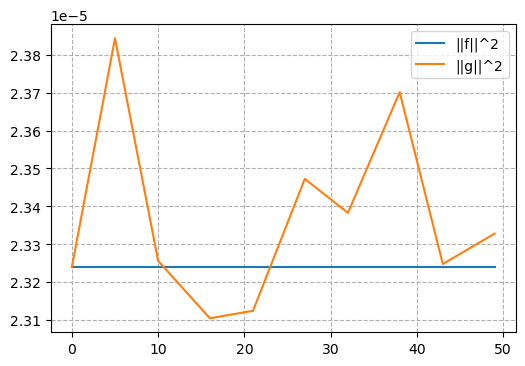

In [19]:
p = np.linalg.norm(het_vols[0])
pf = [p**2 for _ in range(n_vols)]
pg = [np.linalg.norm(g)**2 for g in het_vols]

plt.figure(figsize=(6,4))
plt.plot(vol_idx, pf, label='||f||^2')
plt.plot(vol_idx, pg, label='||g||^2')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [20]:
idx = 0

a = np.sum(f * het_vols_rotated[idx]) * dV
b = corr_l2[idx] 

print(a)
print(b)

print(np.round( (abs(a-b) / a) * 100, 3 ))

6.466816549074319e-10
6.177408876913211e-10
4.475


In [21]:
a / b

1.0468493632083686

In [22]:
idx = 0

g_t = transforms.Transform(het_vols_rotated[idx], d=3).inverse_cdf_transform()[0]

a = np.sum(f_t * g_t * sinthetas) * dVsphere 
b = corr_sw[idx] 

print(a)
print(b)

print(np.round( (abs(a-b) / a) * 100, 3 ))

3.479274206961905
3.3608364446780623
3.404


In [23]:
a / b

1.0352405611619069

In [24]:
idx = 0

g_t = transforms.Transform(het_vols[idx], d=3).inverse_cdf_transform()[0]

a = np.sum((f_t - g_t)**2 * sinthetas) * dVsphere

In [25]:
a

0.0

In [26]:
distances_sw[idx]

0.018849955316216437

In [27]:
q = np.array([1 + 1j, 1+ 1j])